# E3 — Token Scalability

## 1. Mục tiêu

Thí nghiệm đánh giá khả năng mở rộng của DeepKoopFormer khi số lượng patch tokens được xử lý bởi Transformer Encoder tăng lên.

Các nội dung khảo sát:

- **Độ chính xác:** Ảnh hưởng của số patch tokens đến MSE và MAE.
- **Chi phí tính toán:** Sự thay đổi thời gian huấn luyện và bộ nhớ GPU.
- **Độ phức tạp mô hình:** Sự thay đổi số lượng tham số khi điều chỉnh Patch Length.
- **So sánh kiến trúc:** Đánh giá PatchTST và KoopPatchTST_Full dưới các cấu hình chia patch khác nhau.

## 2. Thiết kế thực nghiệm

**Dataset:** CMIP6 Wind, sử dụng dữ liệu đã chuẩn bị trong Ablation Study.

**Models:**
- PatchTST
- KoopPatchTST_Full

Giữ cố định Input Sequence Length bằng 120 timestamps và thay đổi Patch Length:

| Sequence Length | Patch Length | Patch Tokens |
|---|---|---|
| 120 | 120 | 1 |
| 120 | 60 | 2 |
| 120 | 30 | 4 |

Sử dụng các patch không chồng lấn, với `stride = patch_len`.

**Cấu hình huấn luyện:**

| Tham số | Giá trị |
|---|---|
| Input Sequence Length | 120 |
| Forecast Horizon | 8 |
| Epochs | 4000 |
| Learning Rate | 0.0003 |
| Optimizer | Adam |
| Seed | 7 |
| d_model | 96 |
| Encoder Layers | 3 |
| Attention Heads | 4 |
| Lyapunov Weight (Full) | 0.1 |

**Tổng số cấu hình:**

3 patch configurations × 2 models = **6 lượt huấn luyện**.

## 3. Phương pháp thực hiện

1. Sử dụng cùng tập Train/Test của CMIP6 Wind.
2. Giữ nguyên Sequence Length và Forecast Horizon.
3. Tạo Sliding Windows theo quy ước của Ablation Study.
4. Khởi tạo mô hình với các Patch Length khác nhau.
5. Kiểm tra số lượng patch tokens trước khi huấn luyện.
6. Huấn luyện 6 cấu hình độc lập, mỗi cấu hình 4000 epochs.
7. Đánh giá Test MSE và MAE trên thang đo gốc.
8. Ghi nhận thời gian huấn luyện, peak GPU memory và số lượng tham số.

## 4. Kết quả đầu ra

- 6 file `.pt` chứa kết quả từng cấu hình.
- Checkpoint hỗ trợ Resume.
- `metrics.csv` gồm kết quả Train/Test.
- Biểu đồ MSE, MAE, Training Time, Peak GPU Memory và Parameters theo số patch tokens.

## 5. Phạm vi và ý nghĩa

Thí nghiệm khảo sát cách cấu hình chia patch ảnh hưởng đến khả năng dự báo và chi phí tính toán của DeepKoopFormer so với PatchTST.

Vì số patch tokens tăng khi Patch Length giảm, thực nghiệm phản ánh đồng thời ảnh hưởng của số token và kích thước patch embedding. Kết quả không được diễn giải như phép đo độc lập hoàn toàn độ phức tạp attention.

Đây là thí nghiệm mở rộng do nhóm thiết kế, sử dụng kiến trúc từ Ablation Study.

E3 TOKEN SCALABILITY: ENVIRONMENT SETUP

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch

# 1. Reproducibility
SEED = 7

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 2. Locate project root
PROJECT_ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "experiments" / "05_ablation"
            / "02_ablation_model.ipynb"
        ).is_file()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate project root")

# 3. Directories
ABLATION_DIR = PROJECT_ROOT / "experiments" / "05_ablation"
SCALABILITY_DIR = PROJECT_ROOT / "experiments" / "06_scalability"

DATA_DIR = ABLATION_DIR / "data"
MODEL_NOTEBOOK = ABLATION_DIR / "02_ablation_model.ipynb"
DATA_PATH = DATA_DIR / "cmip6_wind_ablation.pt"

RESULTS_DIR = SCALABILITY_DIR / "results" / "e3_token_scaling"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 4. Experimental configuration
DATASET_NAME = "CMIP6 Wind"

SEQ_LEN = 120
PATCH_LENGTHS = [120, 60, 30]
HORIZON = 8

MODEL_NAMES = [
    "PatchTST",
    "KoopPatchTST_Full"
]

EPOCHS = 4000
LEARNING_RATE = 3e-4

D_MODEL = 96
LYAP_WEIGHT = 0.1

# 5. Validate files
assert MODEL_NOTEBOOK.is_file()
assert DATA_PATH.is_file()

# 6. Calculate actual patch-token counts
TOKEN_COUNTS = {}

for patch_len in PATCH_LENGTHS:

    assert SEQ_LEN % patch_len == 0

    stride = patch_len
    n_tokens = (SEQ_LEN - patch_len) // stride + 1

    TOKEN_COUNTS[patch_len] = n_tokens

# 7. Summary
print("=== E3: TOKEN SCALABILITY ===")

print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset:", DATASET_NAME)
print("Models:", MODEL_NAMES)

print("\nSequence length:", SEQ_LEN)
print("Patch lengths:", PATCH_LENGTHS)
print("Patch token counts:", TOKEN_COUNTS)
print("Horizon:", HORIZON)

print("\nEpochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Seed:", SEED)

total = len(PATCH_LENGTHS) * len(MODEL_NAMES)

print("\nTotal configurations:", total)
print("Results directory:", RESULTS_DIR)
print("\nENVIRONMENT SETUP PASSED!")


=== E3: TOKEN SCALABILITY ===
Project: c:\Users\Win 11 New\Desktop\pa gk
Device: cuda
GPU: Quadro T1000

Dataset: CMIP6 Wind
Models: ['PatchTST', 'KoopPatchTST_Full']

Sequence length: 120
Patch lengths: [120, 60, 30]
Patch token counts: {120: 1, 60: 2, 30: 4}
Horizon: 8

Epochs: 4000
Learning rate: 0.0003
Seed: 7

Total configurations: 6
Results directory: c:\Users\Win 11 New\Desktop\pa gk\experiments\06_scalability\results\e3_token_scaling

ENVIRONMENT SETUP PASSED!


LOAD AND VALIDATE CMIP6 WIND

In [2]:
# 1. Load dataset from Ablation
bundle = torch.load(
    DATA_PATH,
    map_location="cpu",
    weights_only=True
)

# 2. Extract data
train_data = bundle["train"].float()
test_data = bundle["test"].float()

N_CHANNELS = bundle["input_dim"]

# 3. Validate dimensions
assert train_data.shape == (2336, 5)
assert test_data.shape == (584, 5)
assert N_CHANNELS == 5

# 4. Validate numerical values
assert torch.isfinite(train_data).all()
assert torch.isfinite(test_data).all()

# 5. Summary
print("=== E3 DATASET VALIDATION ===")
print("Dataset:", DATASET_NAME)
print("Train shape:", tuple(train_data.shape))
print("Test shape:", tuple(test_data.shape))
print("Channels:", N_CHANNELS)

print("\nSequence length:", SEQ_LEN)
print("Forecast horizon:", HORIZON)
print("Patch token counts:", TOKEN_COUNTS)

print("\nDATASET VALIDATION PASSED!")


=== E3 DATASET VALIDATION ===
Dataset: CMIP6 Wind
Train shape: (2336, 5)
Test shape: (584, 5)
Channels: 5

Sequence length: 120
Forecast horizon: 8
Patch token counts: {120: 1, 60: 2, 30: 4}

DATASET VALIDATION PASSED!


c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


CREATE SLIDING WINDOWS

In [3]:
# 1. Sliding-window function
def create_windows(data, seq_len, horizon):

    X, Y = [], []

    # Same convention as Ablation Study
    n_windows = len(data) - seq_len - horizon

    for i in range(n_windows):

        # Input: 120 timestamps
        X.append(
            data[i:i + seq_len]
        )

        # Target: next 8 timestamps
        Y.append(
            data[i + seq_len:i + seq_len + horizon]
            .T.reshape(-1)
        )

    return torch.stack(X), torch.stack(Y)


# 2. Create Train/Test windows
X_train, Y_train = create_windows(
    train_data, SEQ_LEN, HORIZON
)

X_test, Y_test = create_windows(
    test_data, SEQ_LEN, HORIZON
)

# 3. Validate shapes
assert X_train.shape == (2208, 120, 5)
assert Y_train.shape == (2208, 40)

assert X_test.shape == (456, 120, 5)
assert Y_test.shape == (456, 40)

# 4. Validate first window
torch.testing.assert_close(
    X_train[0],
    train_data[:SEQ_LEN]
)

torch.testing.assert_close(
    Y_train[0],
    train_data[
        SEQ_LEN:SEQ_LEN + HORIZON
    ].T.reshape(-1)
)

# 5. Validate numerical values
for tensor in [X_train, Y_train, X_test, Y_test]:
    assert torch.isfinite(tensor).all()

# 6. Summary
print("=== E3 SLIDING WINDOWS ===")

print("\nTrain:")
print("X_train:", tuple(X_train.shape))
print("Y_train:", tuple(Y_train.shape))

print("\nTest:")
print("X_test:", tuple(X_test.shape))
print("Y_test:", tuple(Y_test.shape))

print("\nPatch configurations:", PATCH_LENGTHS)
print("Token counts:", TOKEN_COUNTS)

print("\nSLIDING WINDOWS PASSED!")


=== E3 SLIDING WINDOWS ===

Train:
X_train: (2208, 120, 5)
Y_train: (2208, 40)

Test:
X_test: (456, 120, 5)
Y_test: (456, 40)

Patch configurations: [120, 60, 30]
Token counts: {120: 1, 60: 2, 30: 4}

SLIDING WINDOWS PASSED!


LOAD AND VALIDATE MODEL ARCHITECTURE

In [4]:
import sys

# 1. Load existing model definitions
sys.path.insert(0, str(ABLATION_DIR))

from train_ablation_v2 import load_model_notebook

model_definitions = load_model_notebook(MODEL_NOTEBOOK)

PatchTSTBaseline = model_definitions["PatchTSTBaseline"]
Koopformer_PatchTST = model_definitions["Koopformer_PatchTST"]


# 2. Model factory for Token Scaling
def create_e3_model(model_name, patch_len):

    if model_name == "PatchTST":

        model = PatchTSTBaseline(
            input_dim=N_CHANNELS,
            seq_len=SEQ_LEN,
            horizon=HORIZON,
            patch_len=patch_len,
            d_model=D_MODEL
        )

        koop_attr = None
        lyap_weight = 0.0

    elif model_name == "KoopPatchTST_Full":

        model = Koopformer_PatchTST(
            input_dim=N_CHANNELS,
            seq_len=SEQ_LEN,
            horizon=HORIZON,
            patch_len=patch_len,
            d_model=D_MODEL
        )

        koop_attr = "koop"
        lyap_weight = LYAP_WEIGHT

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return model, koop_attr, lyap_weight


# 3. Validate all six model configurations
results = []

for patch_len in PATCH_LENGTHS:

    for model_name in MODEL_NAMES:

        model, koop_attr, lyap_weight = (
            create_e3_model(model_name, patch_len)
        )

        model = model.to(DEVICE)
        model.eval()

        dummy_input = torch.zeros(
            2, SEQ_LEN, N_CHANNELS,
            device=DEVICE
        )

        # 4. Check actual patch embeddings
        with torch.no_grad():

            patches = model.backbone.patch(dummy_input)
            prediction = model(dummy_input)

        actual_tokens = patches.shape[1]
        expected_tokens = TOKEN_COUNTS[patch_len]

        assert actual_tokens == expected_tokens

        assert patches.shape == (
            2, expected_tokens, D_MODEL
        )

        assert prediction.shape == (
            2, N_CHANNELS * HORIZON
        )

        assert torch.isfinite(prediction).all()

        # 5. Verify architecture
        assert model.backbone.patch.conv.kernel_size == (
            patch_len,
        )

        assert model.backbone.patch.conv.stride == (
            patch_len,
        )

        assert len(model.backbone.encoder.layers) == 3

        # Number of trainable parameters
        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )

        results.append({
            "Model": model_name,
            "Patch Length": patch_len,
            "Patch Tokens": actual_tokens,
            "Total Tokens": actual_tokens + 1,
            "Parameters": n_params,
            "Prediction Shape": str(tuple(prediction.shape)),
            "Lyap Weight": lyap_weight,
            "Status": "PASSED"
        })

        del model


# 6. Summary
model_df = pd.DataFrame(results)

print("=== E3 MODEL VALIDATION ===")
display(model_df)

assert len(model_df) == 6
assert (model_df["Status"] == "PASSED").all()

print("\nTotal configurations:", len(model_df))
print("All patch token counts verified.")
print("MODEL VALIDATION PASSED!")


=== E3 MODEL VALIDATION ===


,Model,Patch Length,Patch Tokens,Total Tokens,Parameters,Prediction Shape,Lyap Weight,Status
0,PatchTST,120,1,2,230440,"(2, 40)",0.0,PASSED
1,KoopPatchTST_Full,120,1,2,248968,"(2, 40)",0.1,PASSED
2,PatchTST,60,2,3,201640,"(2, 40)",0.0,PASSED
3,KoopPatchTST_Full,60,2,3,220168,"(2, 40)",0.1,PASSED
4,PatchTST,30,4,5,187240,"(2, 40)",0.0,PASSED
5,KoopPatchTST_Full,30,4,5,205768,"(2, 40)",0.1,PASSED



Total configurations: 6
All patch token counts verified.
MODEL VALIDATION PASSED!


E3 FULL TRAINING + CHECKPOINT + METRICS

In [5]:
import time
import gc
import hashlib
import torch.optim as optim

from train_ablation_v2 import (
    seed_everything,
    loss_parts,
    snapshot_rng,
    restore_rng,
    atomic_torch_save,
    safe_load,
    predict_cpu_tensor
)

CHECKPOINT_EVERY = 250

CKPT_DIR = RESULTS_DIR / "checkpoints"
MODEL_DIR = RESULTS_DIR / "models"
CSV_PATH = RESULTS_DIR / "metrics.csv"

CKPT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_SHA = hashlib.sha256(
    MODEL_NOTEBOOK.read_bytes()
).hexdigest()

DATA_SHA = hashlib.sha256(
    train_data.numpy().tobytes()
    + test_data.numpy().tobytes()
).hexdigest()

# Min-Max statistics saved during Ablation preprocessing
SCALER_MIN = np.asarray(
    bundle["scaler_min"], dtype=np.float64
).reshape(-1)

SCALER_MAX = np.asarray(
    bundle["scaler_max"], dtype=np.float64
).reshape(-1)

SCALER_RANGE = SCALER_MAX - SCALER_MIN

assert SCALER_RANGE.shape == (N_CHANNELS,)
assert np.all(SCALER_RANGE > 0)


# 1. EVALUATION

def evaluate_split(model, X, Y):

    prediction = predict_cpu_tensor(
        model, X, DEVICE, 256
    ).numpy().astype(np.float64)

    target = Y.numpy().astype(np.float64)

    # Scaled errors
    scaled_diff = prediction - target

    # Feature-major output: (N, channels * horizon)
    diff_3d = scaled_diff.reshape(
        -1, N_CHANNELS, HORIZON
    ).transpose(0, 2, 1)

    # Convert errors to original wind-speed units
    raw_diff = diff_3d * SCALER_RANGE.reshape(
        1, 1, N_CHANNELS
    )

    return {
        "MSE": float(np.mean(raw_diff ** 2)),
        "MAE": float(np.mean(np.abs(raw_diff))),
        "MSE_Scaled": float(np.mean(scaled_diff ** 2)),
        "MAE_Scaled": float(np.mean(np.abs(scaled_diff)))
    }


# 2. UPDATE METRICS.CSV FROM COMPLETED MODELS

def update_metrics_csv():

    rows = []

    for path in sorted(MODEL_DIR.glob("*.pt")):

        artifact = safe_load(path)
        cfg = artifact["config"]

        for split in ("Train", "Test"):

            rows.append({
                "Dataset": cfg["dataset"],
                "Model": cfg["model"],
                "Seq_Len": cfg["seq_len"],
                "Patch_Len": cfg["patch_len"],
                "Patch_Tokens": cfg["patch_tokens"],
                "Total_Tokens": cfg["patch_tokens"] + 1,
                "Split": split,

                "Train_Windows": artifact["train_windows"],
                "Test_Windows": artifact["test_windows"],

                "Parameters": artifact["parameters"],
                "Epochs": cfg["epochs"],

                **artifact["metrics"][split],

                "Train_Seconds": artifact["train_seconds"],
                "Seconds_Per_Epoch": (
                    artifact["train_seconds"] / cfg["epochs"]
                ),
                "Peak_GPU_MB": artifact["peak_gpu_mb"],
                "Seed": cfg["seed"]
            })

    if rows:

        df = pd.DataFrame(rows).sort_values(
            ["Patch_Tokens", "Model", "Split"]
        )

        temp_path = CSV_PATH.with_suffix(".csv.tmp")
        df.to_csv(temp_path, index=False)
        temp_path.replace(CSV_PATH)

    return len(rows)


# 3. FULL TRAINING — 6 CONFIGURATIONS

run_index = 0
total_runs = len(PATCH_LENGTHS) * len(MODEL_NAMES)

for patch_len in PATCH_LENGTHS:

    for model_name in MODEL_NAMES:

        run_index += 1
        n_tokens = TOKEN_COUNTS[patch_len]

        slug = (
            f"cmip6_wind_{model_name.lower()}_"
            f"p{patch_len}_t{n_tokens}"
        )

        pt_path = MODEL_DIR / f"{slug}.pt"
        ckpt_path = CKPT_DIR / slug / "latest.pt"

        config = {
            "dataset": DATASET_NAME,
            "model": model_name,
            "seq_len": SEQ_LEN,
            "patch_len": patch_len,
            "patch_tokens": n_tokens,
            "stride": patch_len,
            "horizon": HORIZON,
            "channels": N_CHANNELS,
            "d_model": D_MODEL,
            "epochs": EPOCHS,
            "lr": LEARNING_RATE,
            "seed": SEED,
            "lyap_weight": (
                LYAP_WEIGHT
                if model_name == "KoopPatchTST_Full"
                else 0.0
            ),
            "data_sha256": DATA_SHA,
            "model_sha256": MODEL_SHA,
            "device": str(DEVICE)
        }

        print(
            f"\n[{run_index}/{total_runs}] "
            f"{model_name} | "
            f"Patch={patch_len} | "
            f"Tokens={n_tokens}",
            flush=True
        )

        # Skip completed configurations
        if pt_path.exists():

            saved = safe_load(pt_path)

            if saved["config"] != config:
                raise ValueError(
                    f"Config mismatch: {pt_path}"
                )

            update_metrics_csv()
            print("SKIP: already completed")
            continue

        # 4. Initialize model
        seed_everything(SEED)

        model, koop_attr, lyap_weight = (
            create_e3_model(model_name, patch_len)
        )

        model = model.to(DEVICE)

        optimizer = optim.Adam(
            model.parameters(),
            lr=LEARNING_RATE
        )

        X = X_train.to(DEVICE)
        Y = Y_train.to(DEVICE)

        start_epoch = 0
        old_seconds = 0.0
        old_peak = 0.0

        # 5. Resume checkpoint if available
        if ckpt_path.exists():

            ckpt = safe_load(ckpt_path)

            if ckpt["config"] != config:
                raise ValueError(
                    f"Checkpoint mismatch: {ckpt_path}"
                )

            model.load_state_dict(
                ckpt["model_state_dict"]
            )

            optimizer.load_state_dict(
                ckpt["optimizer_state_dict"]
            )

            for state in optimizer.state.values():
                for key, value in state.items():
                    if torch.is_tensor(value):
                        state[key] = value.to(DEVICE)

            start_epoch = ckpt["epoch"]
            old_seconds = ckpt["train_seconds"]
            old_peak = ckpt["peak_gpu_mb"]

            restore_rng(ckpt["rng"])

            print(
                f"RESUME: epoch {start_epoch}/{EPOCHS}",
                flush=True
            )

        # 6. Start training
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        train_seconds = old_seconds
        peak_mb = old_peak

        for epoch in range(start_epoch, EPOCHS):

            model.train()
            optimizer.zero_grad()

            # Same training loss as Ablation
            loss, mse, lyap = loss_parts(
                model, X, Y, lyap_weight
            )

            if not torch.isfinite(loss).item():
                raise FloatingPointError(
                    f"Non-finite loss at epoch {epoch + 1}"
                )

            loss.backward()
            optimizer.step()

            # Print every 500 epochs
            if (epoch + 1) % 500 == 0:

                print(
                    f"  Epoch {epoch + 1}/{EPOCHS} | "
                    f"MSE={mse.item():.6f} | "
                    f"Loss={loss.item():.6f}",
                    flush=True
                )

            # 7. Save checkpoint every 250 epochs
            if (
                (epoch + 1) % CHECKPOINT_EVERY == 0
                or epoch + 1 == EPOCHS
            ):

                if DEVICE.type == "cuda":

                    torch.cuda.synchronize()

                    peak_mb = max(
                        old_peak,
                        torch.cuda.max_memory_allocated()
                        / 1024**2
                    )

                train_seconds = (
                    old_seconds
                    + time.perf_counter() - start_time
                )

                atomic_torch_save(
                    {
                        "config": config,
                        "epoch": epoch + 1,
                        "model_state_dict": model.state_dict(),
                        "optimizer_state_dict": optimizer.state_dict(),
                        "train_seconds": train_seconds,
                        "peak_gpu_mb": peak_mb,
                        "rng": snapshot_rng()
                    },
                    ckpt_path
                )

        # 8. Evaluate Train and Test
        train_metrics = evaluate_split(
            model, X_train, Y_train
        )

        test_metrics = evaluate_split(
            model, X_test, Y_test
        )

        # 9. Build completed model artifact
        artifact = {
            "config": config,

            "model_state_dict": {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            },

            "scaler": {
                "min": SCALER_MIN.tolist(),
                "max": SCALER_MAX.tolist()
            },

            "metrics": {
                "Train": train_metrics,
                "Test": test_metrics
            },

            "train_windows": len(X_train),
            "test_windows": len(X_test),

            "parameters": sum(
                p.numel()
                for p in model.parameters()
                if p.requires_grad
            ),

            "train_seconds": train_seconds,
            "peak_gpu_mb": peak_mb
        }

        # 10. Save model and update CSV immediately
        atomic_torch_save(artifact, pt_path)

        update_metrics_csv()

        print(
            f"DONE | "
            f"Test MSE={test_metrics['MSE']:.6g} | "
            f"MAE={test_metrics['MAE']:.6g} | "
            f"Time={train_seconds:.1f}s | "
            f"Peak GPU={peak_mb:.1f} MB",
            flush=True
        )

        # 11. Release memory
        del model, optimizer, X, Y
        gc.collect()

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()


# 12. Final summary
csv_rows = update_metrics_csv()

print(
    f"\nFINISHED: {csv_rows // 2}/6 models; "
    f"{csv_rows}/12 CSV rows"
)



[1/6] PatchTST | Patch=120 | Tokens=1
SKIP: already completed

[2/6] KoopPatchTST_Full | Patch=120 | Tokens=1
SKIP: already completed

[3/6] PatchTST | Patch=60 | Tokens=2
SKIP: already completed

[4/6] KoopPatchTST_Full | Patch=60 | Tokens=2
  Epoch 500/4000 | MSE=0.020858 | Loss=0.020858
  Epoch 1000/4000 | MSE=0.012299 | Loss=0.012299
  Epoch 1500/4000 | MSE=0.009117 | Loss=0.009117
  Epoch 2000/4000 | MSE=0.007642 | Loss=0.007642
  Epoch 2500/4000 | MSE=0.006621 | Loss=0.006621
  Epoch 3000/4000 | MSE=0.005902 | Loss=0.005902
  Epoch 3500/4000 | MSE=0.005349 | Loss=0.005349
  Epoch 4000/4000 | MSE=0.005088 | Loss=0.005088
DONE | Test MSE=8.10316 | MAE=2.08321 | Time=131.5s | Peak GPU=131.7 MB

[5/6] PatchTST | Patch=30 | Tokens=4
  Epoch 500/4000 | MSE=0.020252 | Loss=0.020252
  Epoch 1000/4000 | MSE=0.015315 | Loss=0.015315
  Epoch 1500/4000 | MSE=0.012101 | Loss=0.012101
  Epoch 2000/4000 | MSE=0.010174 | Loss=0.010174
  Epoch 2500/4000 | MSE=0.009152 | Loss=0.009152
  Epoch 300

VISUALIZE E3 TOKEN SCALING

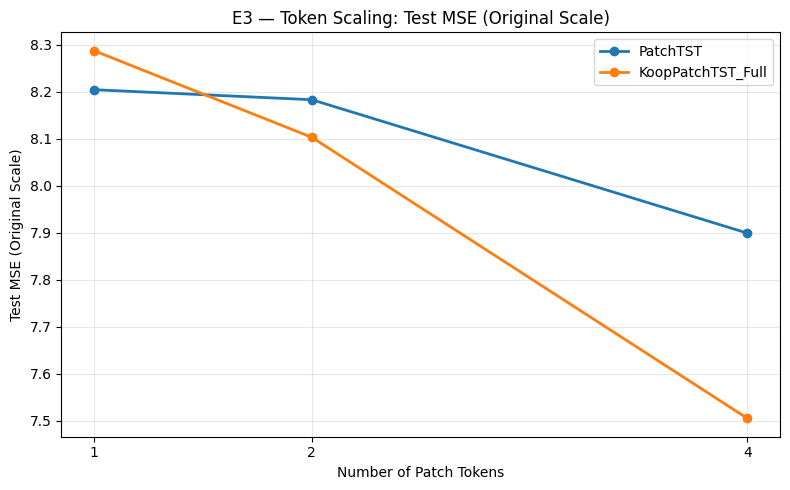

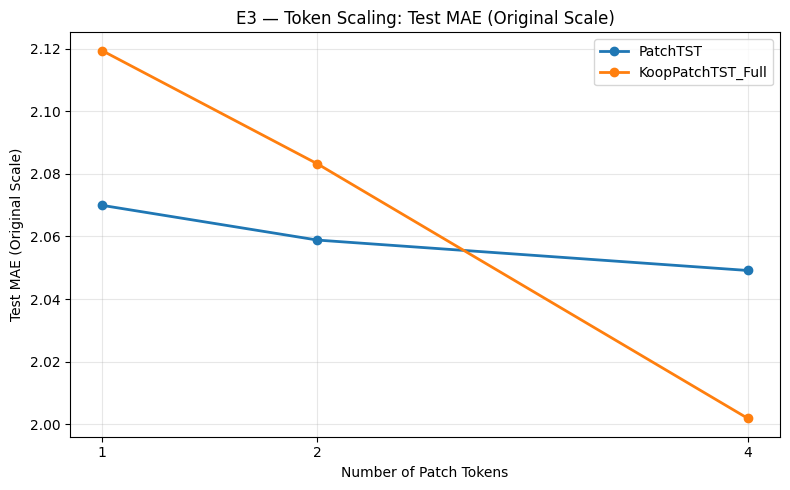

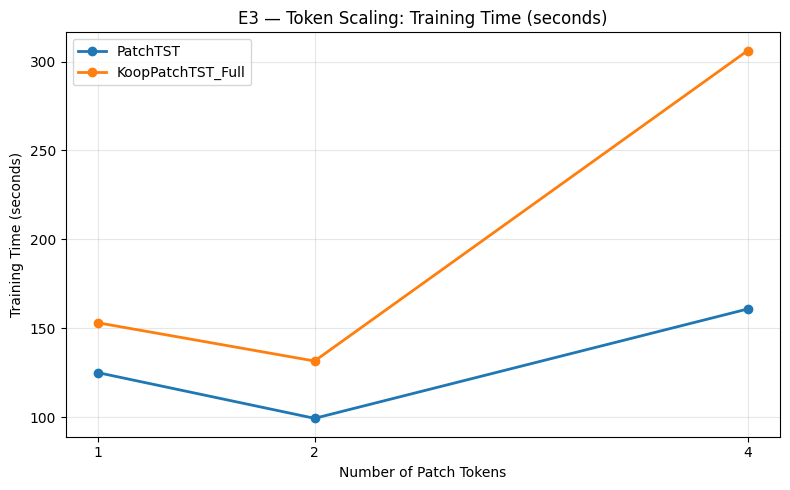

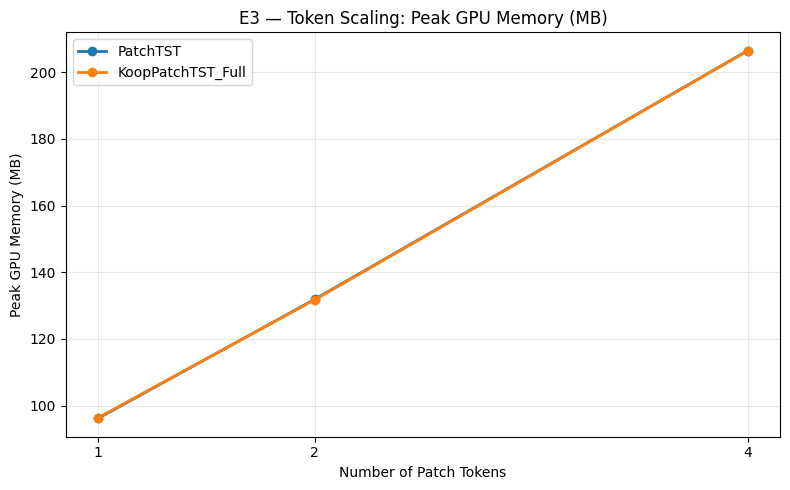

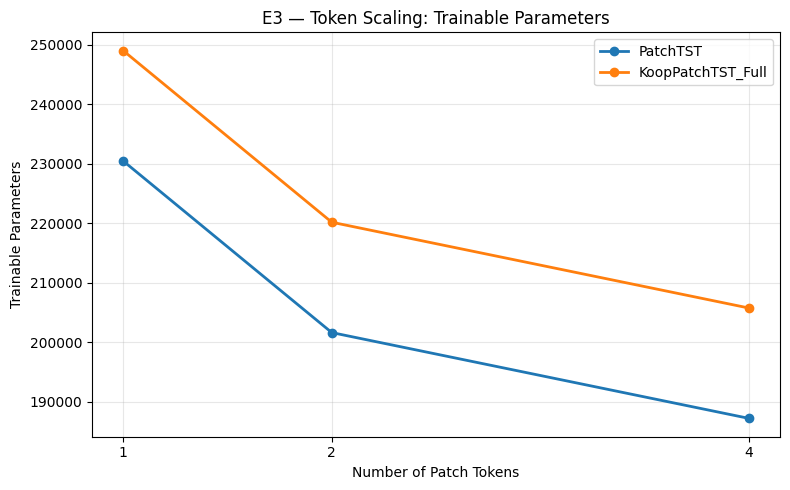


All 5 token scaling figures saved!
Output: c:\Users\Win 11 New\Desktop\pa gk\experiments\06_scalability\results\e3_token_scaling\figures


In [6]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load results
df = pd.read_csv(RESULTS_DIR / "metrics.csv")
df = df[df["Split"] == "Test"].copy()

FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 2. Metrics to visualize
METRICS = {
    "MSE": "Test MSE (Original Scale)",
    "MAE": "Test MAE (Original Scale)",
    "Train_Seconds": "Training Time (seconds)",
    "Peak_GPU_MB": "Peak GPU Memory (MB)",
    "Parameters": "Trainable Parameters"
}

# 3. Plot each metric
for metric, ylabel in METRICS.items():

    plt.figure(figsize=(8, 5))

    for model_name in MODEL_NAMES:

        model_df = df[
            df["Model"] == model_name
        ].sort_values("Patch_Tokens")

        plt.plot(
            model_df["Patch_Tokens"],
            model_df[metric],
            marker="o",
            linewidth=2,
            label=model_name
        )

    plt.title(f"E3 — Token Scaling: {ylabel}")
    plt.xlabel("Number of Patch Tokens")
    plt.ylabel(ylabel)

    plt.xticks([1, 2, 4])
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    # 4. Save figure
    filename = f"cmip6_wind_{metric.lower()}.png"

    plt.savefig(
        FIG_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("\nAll 5 token scaling figures saved!")
print("Output:", FIG_DIR)
